In [1]:
from gene_viz.interpolation.cross_validation import cross_validate
import os
import pandas as pd
import numpy as np

In [2]:
directory1 = '../michack_project_data/'
expression_file = os.path.join(directory1, 'point_expression_data.csv')
coords_file = os.path.join(directory1, 'coords_data.csv')


In [3]:
expression = pd.read_csv(expression_file, index_col=0)
coords = pd.read_csv(coords_file, index_col=0)


In [20]:
sample_coords = np.array(coords)
samples = np.array(expression['PVALB']).ravel()


In [21]:
#LR flipping and stacked
flipped_coords = np.copy(sample_coords)
flipped_coords[:, 0] = -flipped_coords[:, 0]
flipped_samples = np.copy(samples)
#stack
stacked_coords = np.vstack((sample_coords, flipped_coords))
stacked_samples = np.hstack((samples, flipped_samples))
sample_coords = stacked_coords
samples = stacked_samples

Testing with smooth=0
Testing with smooth=0.001
Testing with smooth=0.005
Testing with smooth=0.01
Testing with smooth=0.05
Testing with smooth=0.1


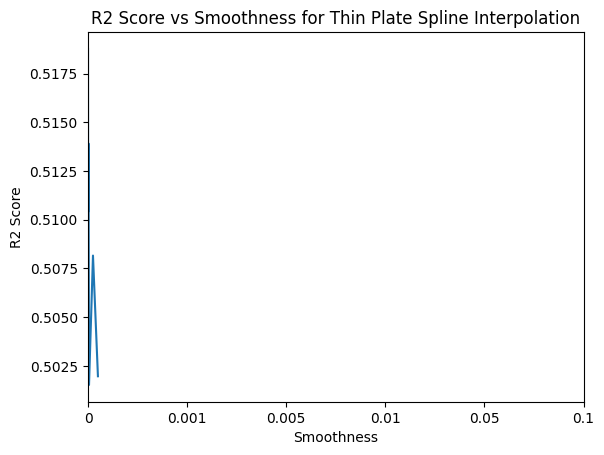

In [ ]:



# Test smoothness values for thin plate spline interpolation
#store scores for different smoothness values

scores = []
for smooth in [0, 0.001 , 0.005, 0.01,0.05, 0.1]:
    print(f"Testing with smooth={smooth}")
    results = cross_validate(
        samples,
        sample_coords,
        methods=['thin_plate'],
        k=10,
        metrics=['r2', 'r', 'mse'],
        method_kwargs={'thin_plate': {'smooth': smooth}},
    )
    scores.append(results[0]['thin_plate']['r2'])

#plot scores
import matplotlib.pyplot as plt
plt.plot(np.arange(len(scores)), scores);
plt.xlabel('Smoothness');
plt.ylabel('R2 Score');
plt.title('R2 Score vs Smoothness for Thin Plate Spline Interpolation');
plt.xticks(np.arange(len(scores)), [0, 0.001, 0.005, 0.01, 0.05, 0.1]);


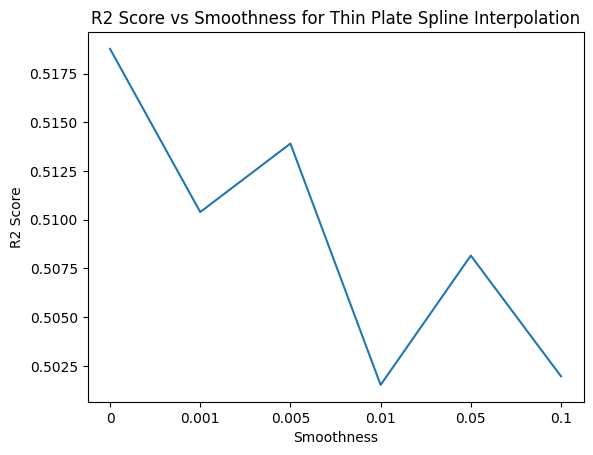

In [9]:
plt.plot(np.arange(len(scores)), scores);
plt.xlabel('Smoothness');
plt.ylabel('R2 Score');
plt.title('R2 Score vs Smoothness for Thin Plate Spline Interpolation');
plt.xticks(np.arange(len(scores)), [0, 0.001, 0.005, 0.01, 0.05, 0.1]);


Testing with power=1
Testing with power=1.5
Testing with power=2
Testing with power=2.5
Testing with power=3
Testing with power=4
Testing with power=5


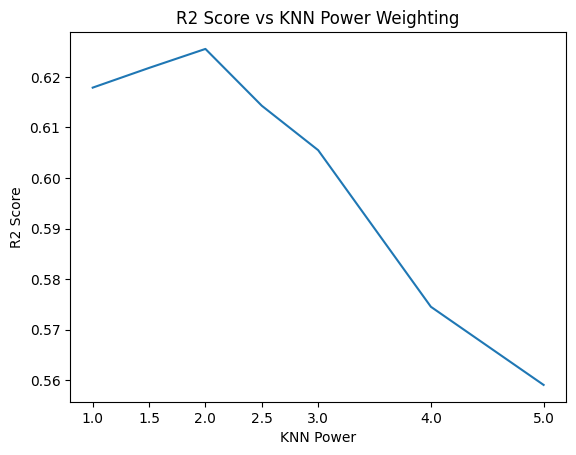

In [66]:
#evaluate KNN power weighting with range of powers
power_scores = []
powers=  [1,1.5, 2,2.5, 3, 4, 5]
for power in powers:
    print(f"Testing with power={power}")
    results = cross_validate(
        samples,
        sample_coords,
        methods=['knn'],
        k=10,
        metrics=['r2', 'r', 'mse'],
        method_kwargs={'knn': {'power': power,'weighting': 'power'}},
    )
    power_scores.append(results[0]['knn']['r2'])

#plot power scores
plt.figure()
plt.plot(powers, power_scores);
plt.xlabel('KNN Power');
plt.ylabel('R2 Score')  ;
plt.title('R2 Score vs KNN Power Weighting');
plt.xticks(powers);

Testing with sigma=0.1
Testing with sigma=0.5
Testing with sigma=1
Testing with sigma=2
Testing with sigma=3
Testing with sigma=4
Testing with sigma=5
Testing with sigma=6
Testing with sigma=10


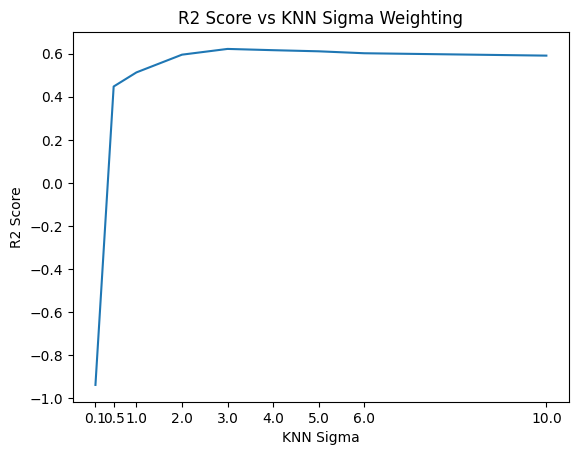

In [67]:
#test sigmas for gaussian weighting 
sigma_scores = []
sigmas = [0.1, 0.5, 1, 2,3,4, 5,6, 10]
for sigma in sigmas:
    print(f"Testing with sigma={sigma}")
    results = cross_validate(
        samples,
        sample_coords,
        methods=['knn'],
        k=10,
        metrics=['r2', 'r', 'mse'],
        method_kwargs={'knn': {'sigma': sigma, 'weighting': 'gaussian'}},
    )
    sigma_scores.append(results[0]['knn']['r2'])
#plot sigma scores
plt.figure()
plt.plot(sigmas, sigma_scores)
plt.xlabel('KNN Sigma')
plt.ylabel('R2 Score')
plt.title('R2 Score vs KNN Sigma Weighting')
plt.xticks(sigmas)
plt.show()

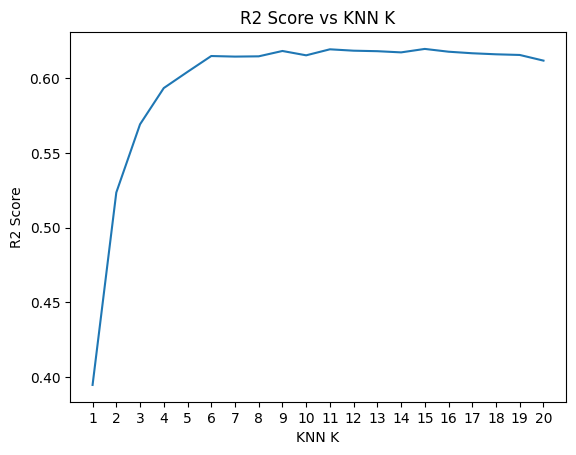

In [68]:
#number of neighbors for KNN
k_scores = []
ks = np.arange(1, 21)
for k in ks:
    #print(f"Testing with k={k}")
    results = cross_validate(
        samples,
        sample_coords,
        methods=['knn'],
        k=10,
        metrics=['r2', 'r', 'mse'],
        method_kwargs={'knn': {'n_neighbors': k}},
    )
    k_scores.append(results[0]['knn']['r2'])
#plot k scores
plt.figure()
plt.plot(ks, k_scores);
plt.xlabel('KNN K');
plt.ylabel('R2 Score');
plt.title('R2 Score vs KNN K');
plt.xticks(ks);

Testing with weight=uniform
Testing with weight=inverse
Testing with weight=power
Testing with weight=gaussian
Testing with weight=softmax


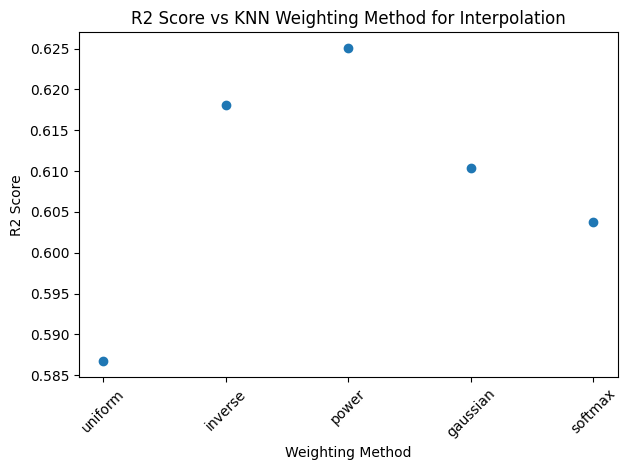

In [69]:
#evaluate a range of KNN distance weightings
scores = {}
for weight in ['uniform', 'inverse','power', 'gaussian','softmax']:
    print(f"Testing with weight={weight}")
    results = cross_validate(
        samples,
        sample_coords,
        methods=['knn'],
        k=10,
        metrics=['r2', 'r', 'mse'],
        method_kwargs={'knn': {'n_neighbors': 10, 'weighting': weight,'power':2,'sigma':4}},
    )
    scores[weight] = results[0]['knn']['r2']

#plot scores
plt.figure();
plt.scatter(scores.keys(), scores.values());
plt.xlabel('Weighting Method');
plt.ylabel('R2 Score');
plt.title('R2 Score vs KNN Weighting Method for Interpolation');
plt.xticks(rotation=45);
plt.tight_layout()

In [22]:
#models to compare
#methods = ['knn', 'thin_plate', 'linear', 'nearest']
#within knn, we can test different weightings and powers
#within thin_plate, we can test different smoothness values
#best for knn is power=2, n_neighbors=10
#for thin plate, smooth=0

methods = ['knn', 'linear', 'thin_plate', 'nearest']
method_kwargs = {
    'knn': {'n_neighbors': 10, 'weighting': 'power', 'power': 2},
    'thin_plate': {'smooth': 0},
    'linear': {},
    'nearest': {}
}
results = cross_validate(
    samples=samples,
    sample_coords=sample_coords,
    methods=methods,
    k=10,
    metrics=['r2', 'r', 'mse'],
    method_kwargs=method_kwargs,
)   

#plot
print(results)



({'knn': {'r2': 0.6569607315837451, 'r': 0.8120806885211914, 'mse': 0.030052179592473145}, 'linear': {'r2': 0.6206198278101986, 'r': 0.7932201243241771, 'mse': 0.03324175878354521}, 'thin_plate': {'r2': 0.5721356241981286, 'r': 0.7761359012672697, 'mse': 0.03750358493571604}, 'nearest': {'r2': 0.45775160371976104, 'r': 0.7320239757341184, 'mse': 0.04749674538875532}}, {'knn': {'r2': [0.6759464988858336, 0.6960841975069316, 0.6601998422344584, 0.640348281818194, 0.6755686711542105, 0.6717815209372733, 0.6174037549500244, 0.6528095937806743, 0.6543189348954741, 0.6251460196743777], 'r': [0.8236451583298237, 0.8348795031146846, 0.8135496076263018, 0.8021523795658597, 0.8229847843929887, 0.8206841306381305, 0.7890678648228007, 0.810755963499504, 0.8100335469790013, 0.7930539462428197], 'mse': [0.0288043321780983, 0.027495971424588293, 0.029645501692154477, 0.03135098510164236, 0.027415235297647687, 0.030310168680059372, 0.0333240463193575, 0.028197638342761205, 0.03176698892842919, 0.03221

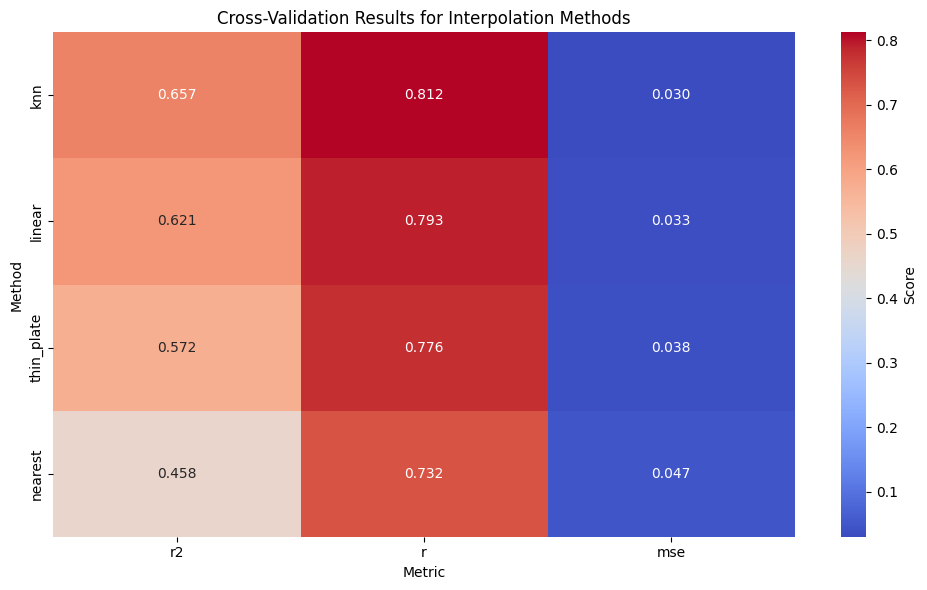

In [23]:
#plot results
#map dictionary to heatmap
import seaborn as sns
import matplotlib.pyplot as plt
results_df = pd.DataFrame(results[0])
results_df = results_df.T
results_df = results_df[['r2', 'r', 'mse']]
results_df.index.name = 'Method'
results_df.columns.name = 'Metric' 
plt.figure(figsize=(10, 6))
#normalise colours per metric
  # Round to 3 decimal places for better readability
sns.heatmap(results_df, annot=True, cmap='coolwarm', fmt='.3f', cbar_kws={'label': 'Score'})
plt.title('Cross-Validation Results for Interpolation Methods')
plt.tight_layout()
